In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread(
    r"C:\OneDrive_local_\Desktop\realtime-organoid-XYZ\High_quality_image_23&24\High_quality_image_2024\test21.jpg"
)
if img is None:
    raise FileNotFoundError("image_loading_failed")

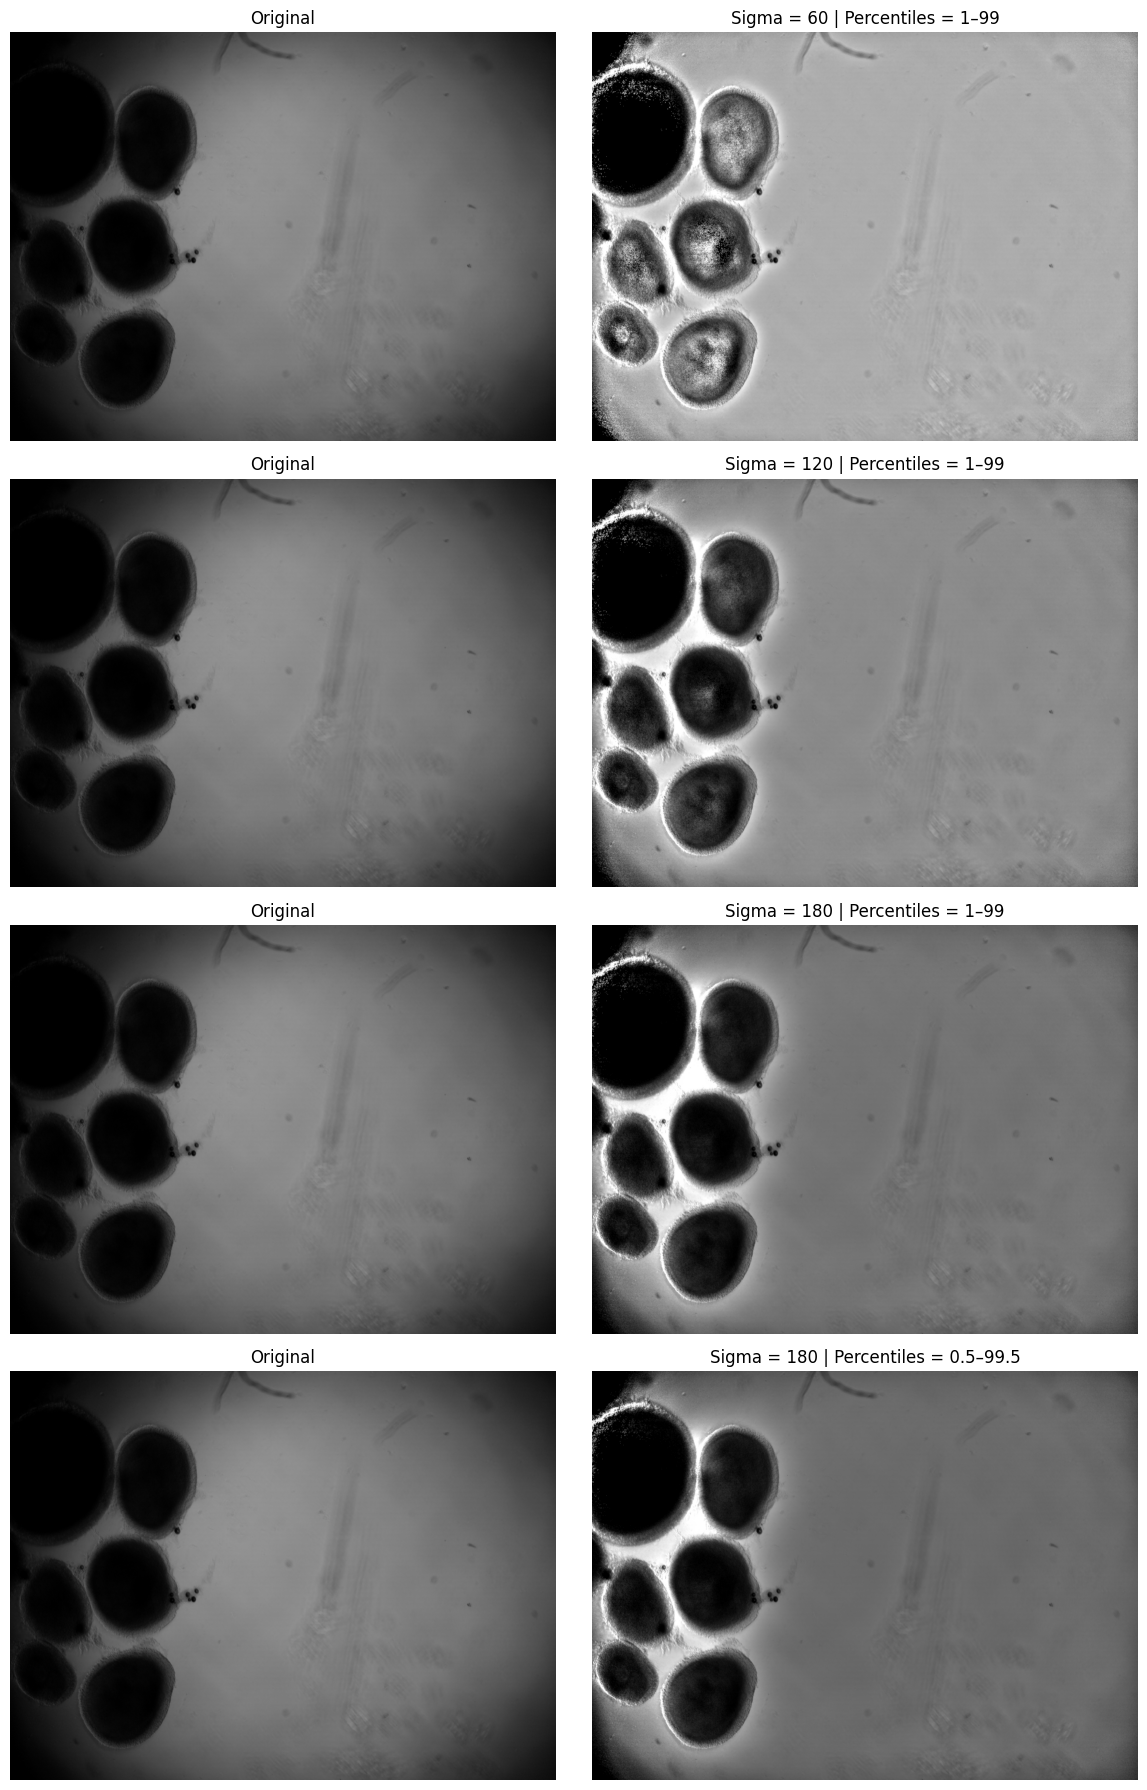

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Convert the loaded image to grayscale and float32.
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)

# Compare three smoothing levels and one gentler contrast stretch.
settings = [
    (60, 1, 99),
    (120, 1, 99),
    (180, 1, 99),
    (180, 0.5, 99.5),
]

# Show the original image beside each processed result.
fig, axes = plt.subplots(4, 2, figsize=(12, 18))

for row, (sigma, p_low, p_high) in enumerate(settings):
    # Estimate the illumination background.
    background = cv2.GaussianBlur(
        gray,
        ksize=(0, 0),
        sigmaX=sigma,
        sigmaY=sigma,
        borderType=cv2.BORDER_DEFAULT
    )

    # Correct uneven illumination.
    corrected = gray / np.maximum(background, 1.0)

    # Stretch the contrast using the selected percentiles.
    low, high = np.percentile(corrected, (p_low, p_high))
    corrected = np.clip(
        (corrected - low) / max(high - low, 1e-6), 0, 1
    )
    corrected = (corrected * 255).astype(np.uint8)

    # Save each result with a unique filename.
    filename = f"corrected_sigma{sigma}_p{p_low}-{p_high}.png"
    if not cv2.imwrite(filename, corrected):
        raise IOError(f"Failed to save {filename}")

    # Display both images using the same grayscale display range.
    axes[row, 0].imshow(gray, cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title("Original")

    axes[row, 1].imshow(corrected, cmap="gray", vmin=0, vmax=255)
    axes[row, 1].set_title(
        f"Sigma = {sigma} | Percentiles = {p_low}–{p_high}"
    )

    for ax in axes[row]:
        ax.axis("off")

# Save and display the complete comparison.
plt.tight_layout()
plt.savefig("parameter_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

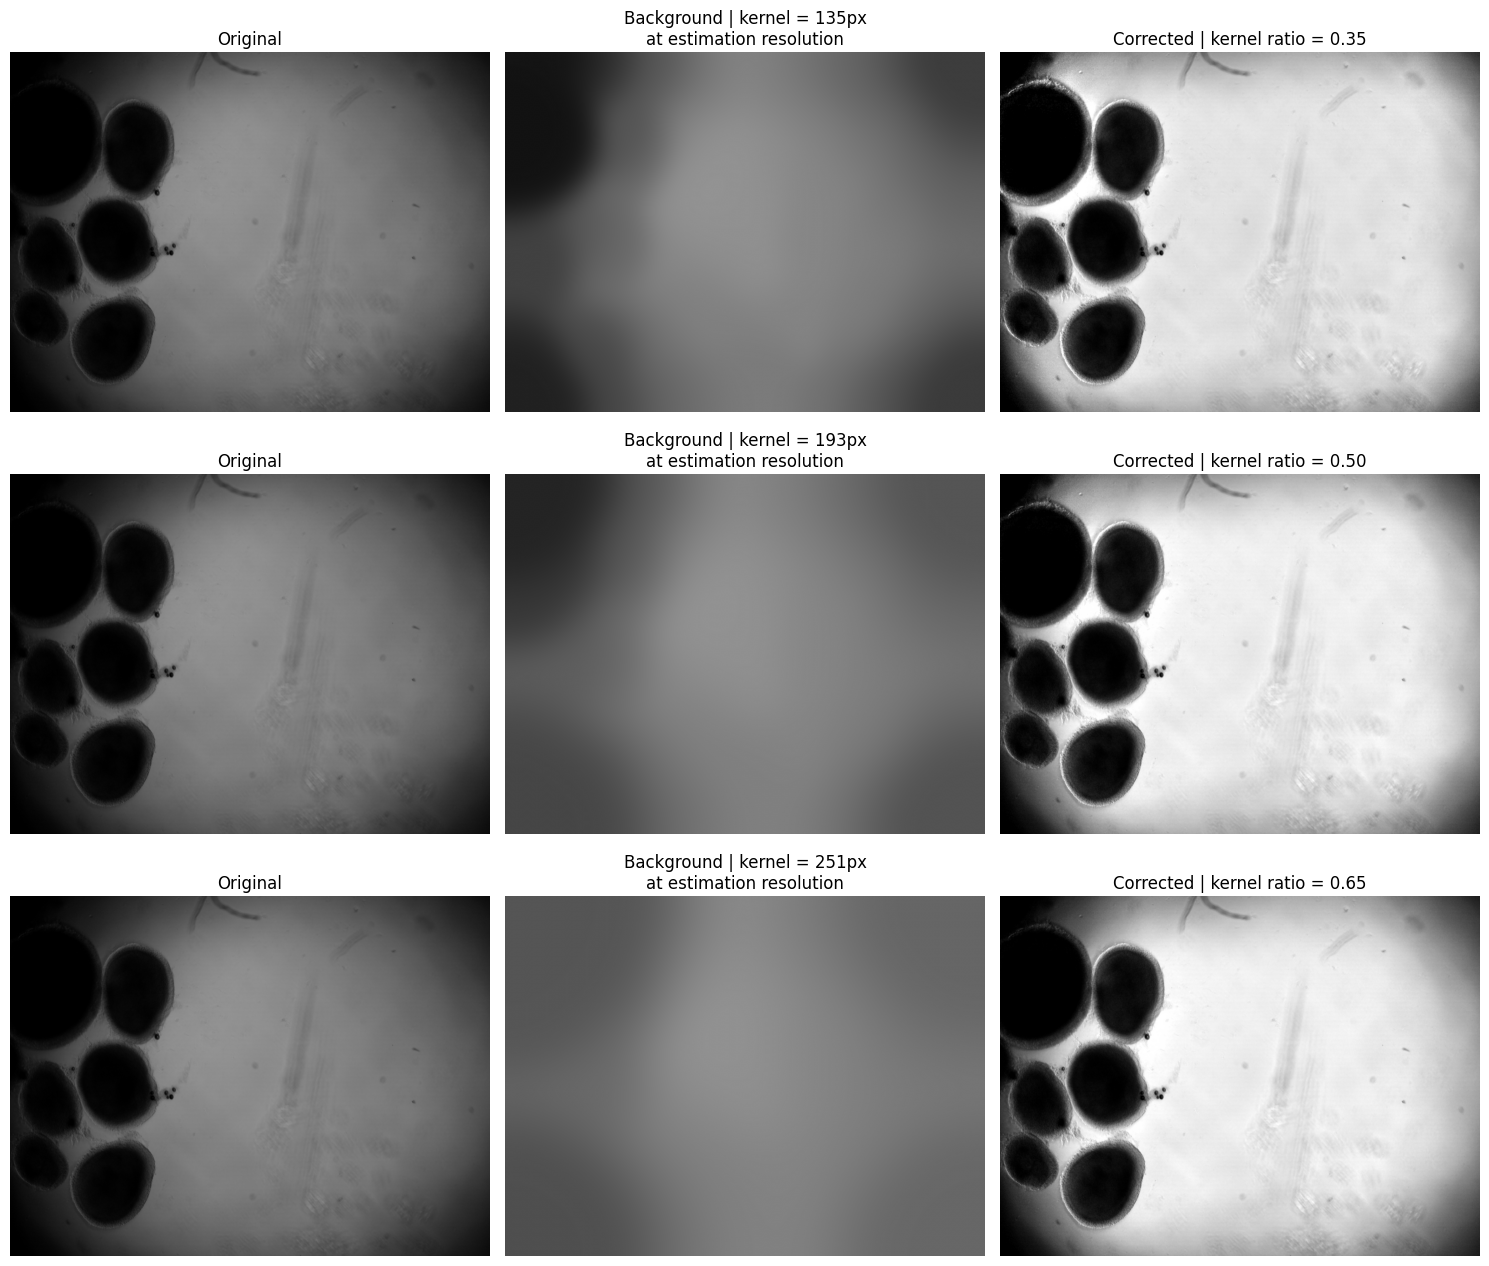

Results saved to: C:\OneDrive_local_\Desktop\realtime-organoid-XYZ\Pre_dataprocess_highQimage_2324\closing_results


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

if img is None:
    raise ValueError("Please load the original image into img first.")

# Start from the original image, not a previously corrected image.
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
h, w = gray.shape

# Estimate the background at a smaller resolution to reduce computation time.
scale = min(1.0, 512 / max(h, w))
small = cv2.resize(
    gray,
    (max(1, round(w * scale)), max(1, round(h * scale))),
    interpolation=cv2.INTER_AREA
)

# Try three kernel sizes relative to the shorter image dimension.
# These are experimental starting points, not universal optimal values.
kernel_ratios = [0.35, 0.50, 0.65]

output_dir = Path("closing_results")
output_dir.mkdir(exist_ok=True)

fig, axes = plt.subplots(3, 3, figsize=(15, 13))

for row, ratio in enumerate(kernel_ratios):
    # Create an odd-sized elliptical kernel.
    kernel_size = max(3, int(round(min(small.shape) * ratio)))
    if kernel_size % 2 == 0:
        kernel_size += 1

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (kernel_size, kernel_size)
    )

    # Fill dark structures in a temporary image to estimate the background.
    background_small = cv2.morphologyEx(
        small,
        cv2.MORPH_CLOSE,
        kernel,
        borderType=cv2.BORDER_REFLECT_101
    )

    # Smooth the estimated background.
    smooth_sigma = max(1.0, kernel_size * 0.10)
    background_small = cv2.GaussianBlur(
        background_small,
        (0, 0),
        sigmaX=smooth_sigma,
        sigmaY=smooth_sigma
    )

    # Restore the background estimate to the original image size.
    background = cv2.resize(
        background_small,
        (w, h),
        interpolation=cv2.INTER_LINEAR
    )

    # Correct the original image using the estimated background.
    ratio_image = gray / np.maximum(background, 1.0)

    # Apply the same percentile settings to each candidate.
    low, high = np.percentile(ratio_image, (0.5, 99.5))
    corrected = np.clip(
        (ratio_image - low) / max(high - low, 1e-6),
        0, 1
    )
    corrected = (corrected * 255).astype(np.uint8)

    # Save the corrected image at its original resolution.
    filename = output_dir / f"corrected_closing_{ratio:.2f}.png"
    if not cv2.imwrite(str(filename), corrected):
        raise IOError(f"Failed to save {filename}")

    # Display the original image, estimated background, and corrected image.
    axes[row, 0].imshow(gray, cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title("Original")

    axes[row, 1].imshow(background, cmap="gray", vmin=0, vmax=255)
    axes[row, 1].set_title(
        f"Background | kernel = {kernel_size}px\n"
        f"at estimation resolution"
    )

    axes[row, 2].imshow(corrected, cmap="gray", vmin=0, vmax=255)
    axes[row, 2].set_title(f"Corrected | kernel ratio = {ratio:.2f}")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(
    output_dir / "closing_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print(f"Results saved to: {output_dir.resolve()}")

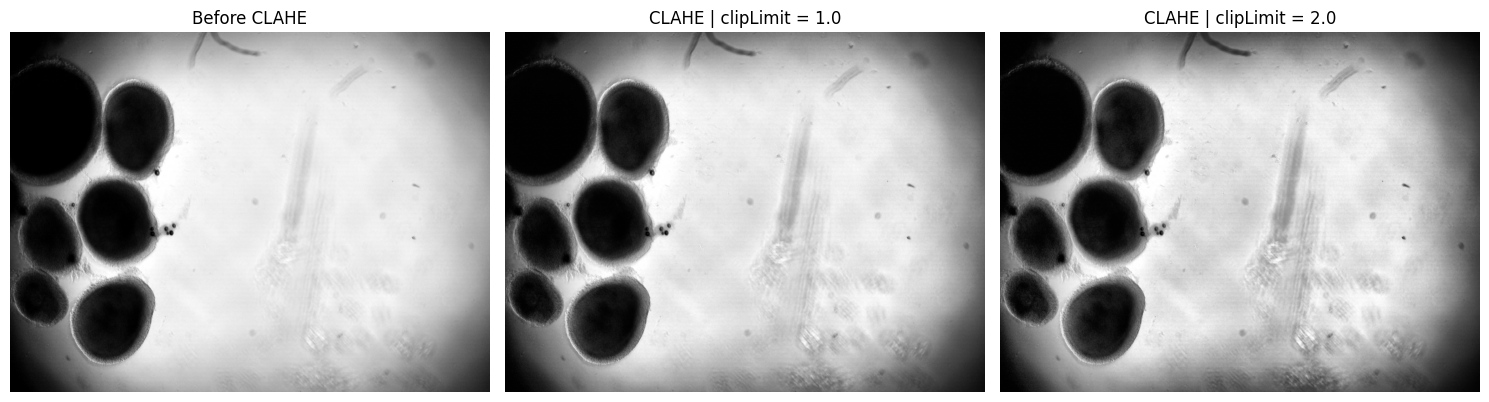

In [5]:
# Use the current illumination-corrected image.
base = corrected.copy()

# Compare two mild CLAHE settings.
# A higher clip limit allows stronger local contrast enhancement.
clip_limits = [1.0, 2.0]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(base, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Before CLAHE")
axes[0].axis("off")

for col, clip_limit in enumerate(clip_limits, start=1):
    # Divide the image into a 4-by-4 grid for local contrast adjustment.
    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=(4, 4)
    )

    # Enhance local contrast without another percentile stretch.
    enhanced = clahe.apply(base)

    axes[col].imshow(enhanced, cmap="gray", vmin=0, vmax=255)
    axes[col].set_title(f"CLAHE | clipLimit = {clip_limit}")
    axes[col].axis("off")

    filename = f"closing_clahe_clip{clip_limit}.png"
    if not cv2.imwrite(filename, enhanced):
        raise IOError(f"Failed to save {filename}")

plt.tight_layout()
plt.savefig("clahe_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

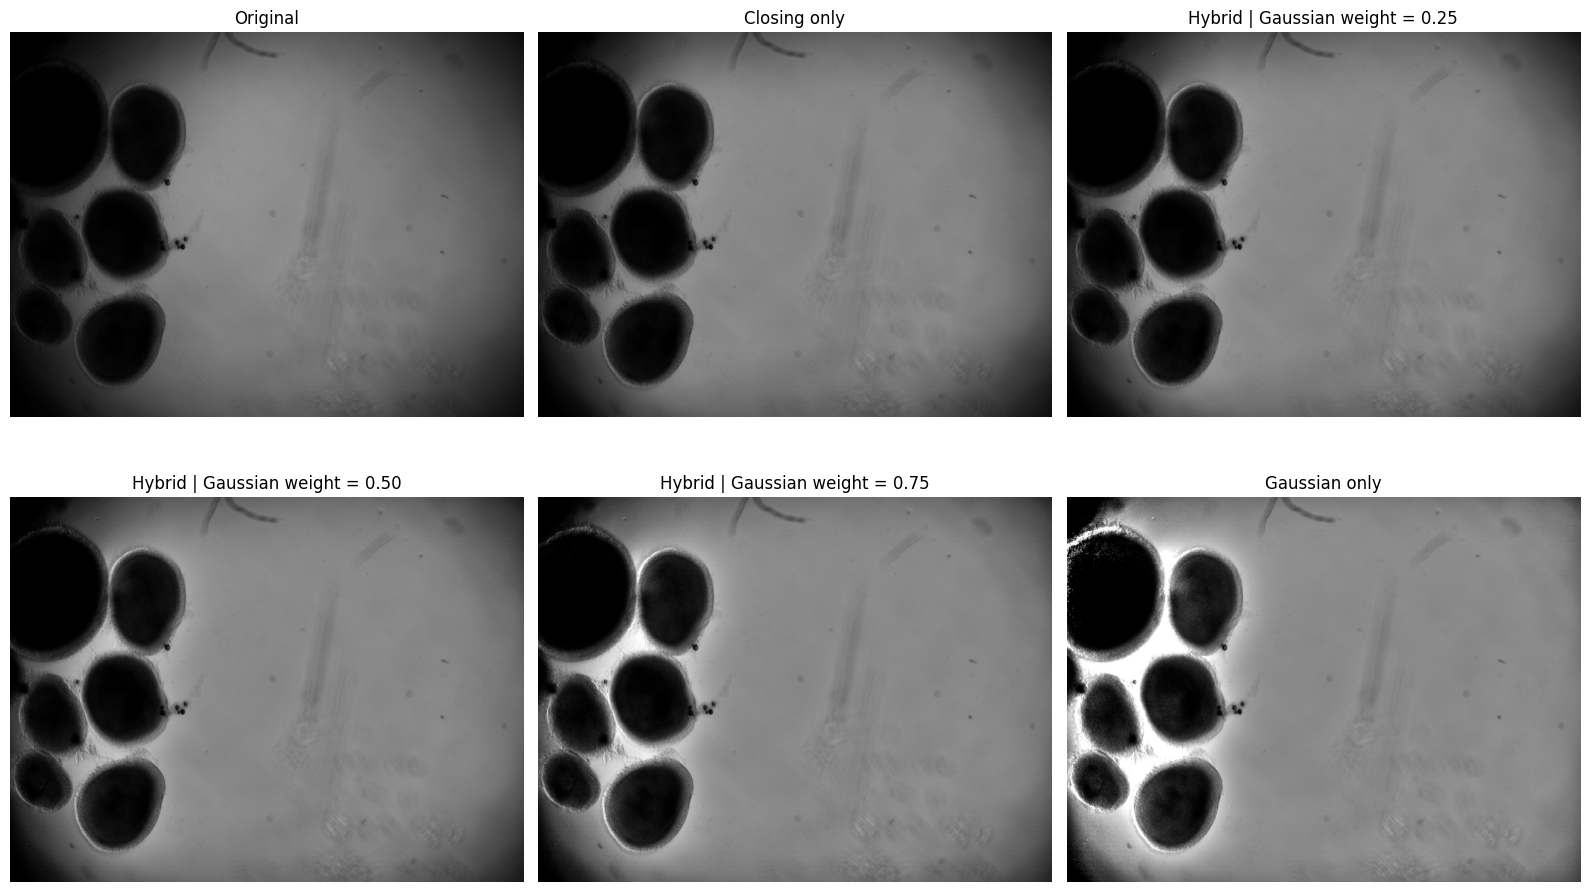

Results saved to: C:\OneDrive_local_\Desktop\realtime-organoid-XYZ\Pre_dataprocess_highQimage_2324\hybrid_results


In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

if img is None:
    raise ValueError("Please load the original image into img first.")

# Start from the original image.
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
h, w = gray.shape

output_dir = Path("hybrid_results")
output_dir.mkdir(exist_ok=True)

# 1. Estimate the background using Gaussian blur.
# Sigma is measured in pixels at the original image resolution.
sigma = 180
background_gaussian = cv2.GaussianBlur(
    gray, (0, 0),
    sigmaX=sigma,
    sigmaY=sigma,
    borderType=cv2.BORDER_DEFAULT
)

# 2. Estimate the background using morphological closing.
# Only the background estimation is performed at a smaller resolution.
scale = min(1.0, 512 / max(h, w))
small = cv2.resize(
    gray,
    (max(1, round(w * scale)), max(1, round(h * scale))),
    interpolation=cv2.INTER_AREA
)

kernel_ratio = 0.65
kernel_size = max(3, round(min(small.shape) * kernel_ratio))
if kernel_size % 2 == 0:
    kernel_size += 1

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (kernel_size, kernel_size)
)

background_small = cv2.morphologyEx(
    small,
    cv2.MORPH_CLOSE,
    kernel,
    borderType=cv2.BORDER_REFLECT_101
)

smooth_sigma = max(1.0, kernel_size * 0.10)
background_small = cv2.GaussianBlur(
    background_small, (0, 0),
    sigmaX=smooth_sigma,
    sigmaY=smooth_sigma
)

background_closing = cv2.resize(
    background_small, (w, h),
    interpolation=cv2.INTER_LINEAR
)

# 3. Blend the background estimates and correct the original image.
alphas = [0.0, 0.25, 0.50, 0.75, 1.0]
ratio_images = []

for alpha in alphas:
    background_hybrid = (
        (1 - alpha) * background_closing
        + alpha * background_gaussian
    )

    ratio_image = gray / np.maximum(background_hybrid, 1.0)
    ratio_images.append(ratio_image)

# 4. Compute shared display limits from evenly sampled pixels.
# Shared limits prevent separate contrast stretching from hiding differences.
step = max(1, int(np.ceil(max(h, w) / 512)))
samples = np.concatenate([
    result[::step, ::step].ravel()
    for result in ratio_images
])
low, high = np.percentile(samples, (0.5, 99.5))

# 5. Display the original and all five correction settings.
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")
axes[0].axis("off")

for index, (alpha, ratio_image) in enumerate(
    zip(alphas, ratio_images), start=1
):
    corrected = np.clip(
        (ratio_image - low) / max(high - low, 1e-6),
        0, 1
    )
    corrected = (corrected * 255).astype(np.uint8)

    if alpha == 0:
        title = "Closing only"
    elif alpha == 1:
        title = "Gaussian only"
    else:
        title = f"Hybrid | Gaussian weight = {alpha:.2f}"

    axes[index].imshow(
        corrected, cmap="gray", vmin=0, vmax=255
    )
    axes[index].set_title(title)
    axes[index].axis("off")

    filename = output_dir / f"hybrid_alpha{alpha:.2f}.png"
    if not cv2.imwrite(str(filename), corrected):
        raise IOError(f"Failed to save {filename}")

plt.tight_layout()
plt.savefig(
    output_dir / "hybrid_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print(f"Results saved to: {output_dir.resolve()}")

In [7]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


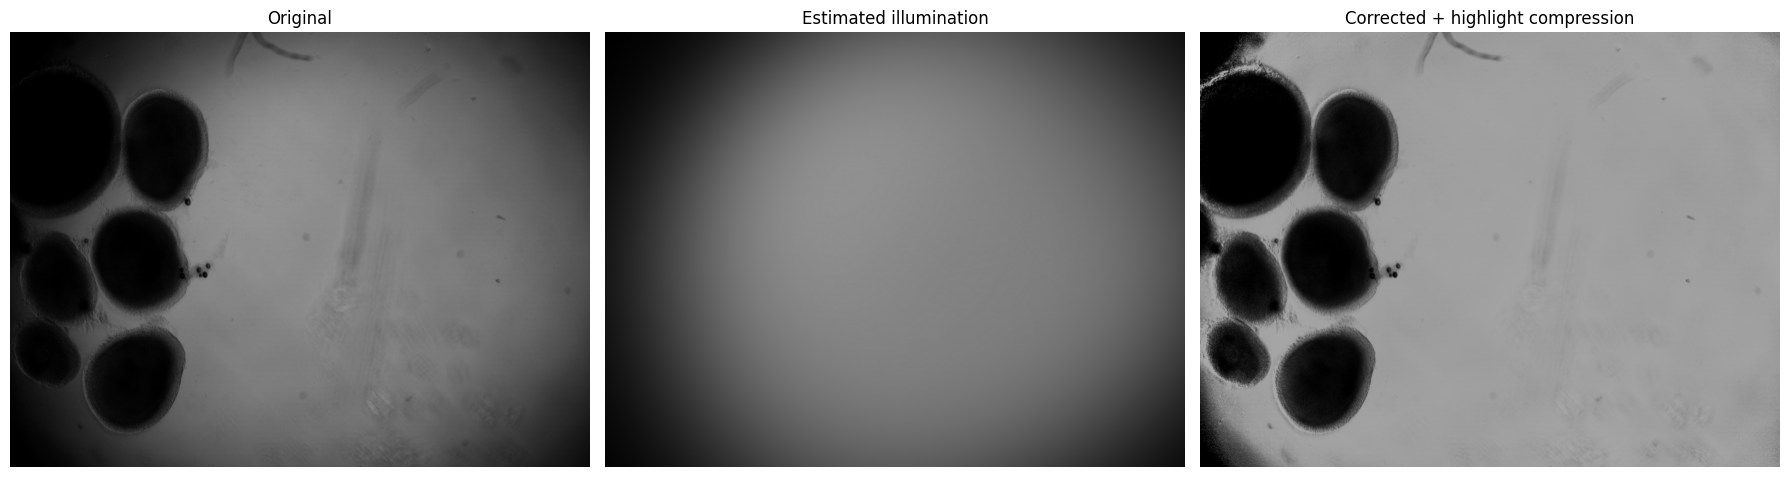

Saved to: C:\OneDrive_local_\Desktop\realtime-organoid-XYZ\Pre_dataprocess_highQimage_2324\organoid_corrected.png


In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from pathlib import Path

# Start from the original image.
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
h, w = gray.shape

# Fit the illumination background at a smaller resolution.
small = cv2.resize(gray, (160, 120), interpolation=cv2.INTER_AREA)
yy, xx = np.mgrid[-1:1:complex(120), -1:1:complex(160)]

# Build a fourth-degree polynomial surface.
degree = 4
powers = [
    (i, j)
    for i in range(degree + 1)
    for j in range(degree + 1 - i)
]
A = np.stack(
    [(xx**i * yy**j).ravel() for i, j in powers],
    axis=1
)
z = np.log(np.maximum(small.ravel(), 1.0))

# Obtain an initial estimate.
initial = np.linalg.lstsq(A, z, rcond=None)[0]

# Reduce the influence of dark organoids on the background fit.
def residual(c):
    r = A @ c - z
    return r * np.where(r > 0, 0.15, 1.0)

def jacobian(c):
    weights = np.where(A @ c - z > 0, 0.15, 1.0)
    return A * weights[:, None]

coefficients = least_squares(
    residual,
    initial,
    jac=jacobian,
    loss="soft_l1",
    f_scale=0.08,
    max_nfev=100
).x

# Exclude dark objects and unusually bright regions from the refined fit.
prediction = A @ coefficients
keep = (
    (z - prediction > -0.25)
    & (z - prediction < 0.15)
).reshape(small.shape)

# Expand the excluded regions slightly to avoid object boundaries.
keep = cv2.erode(
    keep.astype(np.uint8),
    np.ones((3, 3), dtype=np.uint8)
).astype(bool)

k = keep.ravel()
if k.sum() < 10 * len(powers):
    raise ValueError("Too few background pixels remain for a reliable fit.")

# Refine the illumination estimate using the remaining background pixels.
coefficients = least_squares(
    lambda c: A[k] @ c - z[k],
    coefficients,
    jac=lambda c: A[k].copy(),
    loss="soft_l1",
    f_scale=0.05,
    max_nfev=100
).x

# Evaluate the smooth illumination surface at the original resolution.
y = np.linspace(-1, 1, h, dtype=np.float32)[:, None]
x = np.linspace(-1, 1, w, dtype=np.float32)[None, :]

log_background = np.zeros((h, w), dtype=np.float32)
for c, (i, j) in zip(coefficients, powers):
    log_background += c * x**i * y**j

background = np.exp(
    np.clip(log_background, np.log(1.0), np.log(255.0))
)

# Correct illumination without blurring the original organoids.
ratio = gray / np.maximum(background, 3.0)

# Smoothly compress highlights to reduce bright bands between organoids.
# Darker values below the knee remain unchanged.
knee = 0.75
upper = ratio > knee
ratio[upper] = knee + 0.25 * np.tanh(
    (ratio[upper] - knee) / 0.25
)

# Set the output brightness and convert to an 8-bit image.
corrected = np.uint8(np.clip(ratio * 170, 0, 255))

# Display the original image, estimated background, and final result.
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

panels = [
    (gray, "Original"),
    (background, "Estimated illumination"),
    (corrected, "Corrected + highlight compression")
]

for ax, (image, title) in zip(axes, panels):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Save the full-resolution result, including support for Unicode paths.
output_path = Path("organoid_corrected.png")
success, encoded = cv2.imencode(".png", corrected)
if not success:
    raise IOError("Failed to encode the corrected image.")

output_path.write_bytes(encoded.tobytes())
print(f"Saved to: {output_path.resolve()}")